In [7]:
import pandas as pd
import numpy as np

In [8]:
data = pd.read_csv("/Volumes/Backup Plus/vaccine thesis/data/raw/AllVAERSDataCSVS/2025VAERSDATA.csv", encoding="latin1", low_memory=False)
symptoms = pd.read_csv("/Volumes/Backup Plus/vaccine thesis/data/raw/AllVAERSDataCSVS/2025VAERSSYMPTOMS.csv", encoding="latin1", low_memory=False)
vax = pd.read_csv("/Volumes/Backup Plus/vaccine thesis/data/raw/AllVAERSDataCSVS/2025VAERSVAX.csv", encoding="latin1", low_memory=False)

In [9]:
print(data.shape)
print(symptoms.shape)
print(vax.shape)

(40919, 36)
(49156, 12)
(54226, 9)


In [10]:
data.head()

,VAERS_ID,RECVDATE,STATE,AGE_YRS,CAGE_YR,CAGE_MO,SEX,RPT_DATE,SYMPTOM_TEXT,DIED,...,HISTORY,PRIOR_VAX,SPLTTYPE,FORM_VERS,TODAYS_DATE,BIRTH_DEFECT,OFC_VISIT,ER_ED_VISIT,ALLERGIES,ORDER
0,2815014,01/01/2025,NJ,37.0,37.0,NaN,F,NaN,received the SHINGRIX vaccine instead of the F...,NaN,...,NaN,NaN,USGSKUS2024AMR152842,2,01/01/2025,NaN,NaN,NaN,NaN,2
1,2818783,01/01/2025,OH,57.0,57.0,NaN,F,NaN,Pain down arm and weakness for a few days afte...,NaN,...,"high blood pressure, acid reflux, arthritis","soreness in arm after Covid shot, typically la...",NaN,2,01/01/2025,NaN,Y,NaN,percocet,2
2,2818864,01/01/2025,OK,1.0,1.0,0.0,U,NaN,No additional AE; HCP called and reported admi...,NaN,...,NaN,NaN,US0095075132412USA010369,2,12/31/2024,NaN,NaN,NaN,NaN,1
3,2818865,01/01/2025,CO,0.5,NaN,NaN,F,NaN,one of them only received the DTaP-IPV part an...,NaN,...,NaN,NaN,USSA2024SA385084,2,12/31/2024,NaN,NaN,NaN,NaN,1
4,2818871,01/01/2025,VA,2.0,2.0,0.2,F,NaN,Incorrect storage of drug/received Havrix vacc...,NaN,...,NaN,NaN,USGSKUS2024AMR153922,2,01/01/2025,NaN,NaN,NaN,NaN,1


In [11]:
symptoms.head()

,VAERS_ID,SYMPTOM1,SYMPTOMVERSION1,SYMPTOM2,SYMPTOMVERSION2,SYMPTOM3,SYMPTOMVERSION3,SYMPTOM4,SYMPTOMVERSION4,SYMPTOM5,SYMPTOMVERSION5,ORDER
0,791393,Coronary artery bypass,28.0,Dialysis,28.0,End stage renal disease,28.0,Herpes zoster,28.0,Pain in extremity,28.0,2
1,791393,Vaccination failure,28.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
2,791393,Coronary artery bypass,28.0,Dialysis,28.0,End stage renal disease,28.0,Herpes zoster,28.0,Pain,28.0,3
3,791393,Pain in extremity,28.0,Vaccination failure,28.0,NaN,NaN,NaN,NaN,NaN,NaN,3
4,791747,Amenorrhoea,28.0,General physical health deterioration,28.0,Laboratory test,28.0,Malaise,28.0,Menopause,28.0,2


In [12]:
vax.head()

,VAERS_ID,VAX_TYPE,VAX_MANU,VAX_LOT,VAX_DOSE_SERIES,VAX_ROUTE,VAX_SITE,VAX_NAME,ORDER
0,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),2
1,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),2
2,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),3
3,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),3
4,791747,VARZOS,MERCK & CO. INC.,NaN,UNK,OT,NaN,ZOSTER LIVE (ZOSTAVAX),2


In [13]:
print(data.columns.tolist())

['VAERS_ID', 'RECVDATE', 'STATE', 'AGE_YRS', 'CAGE_YR', 'CAGE_MO', 'SEX', 'RPT_DATE', 'SYMPTOM_TEXT', 'DIED', 'DATEDIED', 'L_THREAT', 'ER_VISIT', 'HOSPITAL', 'HOSPDAYS', 'X_STAY', 'DISABLE', 'RECOVD', 'VAX_DATE', 'ONSET_DATE', 'NUMDAYS', 'LAB_DATA', 'V_ADMINBY', 'V_FUNDBY', 'OTHER_MEDS', 'CUR_ILL', 'HISTORY', 'PRIOR_VAX', 'SPLTTYPE', 'FORM_VERS', 'TODAYS_DATE', 'BIRTH_DEFECT', 'OFC_VISIT', 'ER_ED_VISIT', 'ALLERGIES', 'ORDER']


In [14]:
print(symptoms.columns.tolist())

['VAERS_ID', 'SYMPTOM1', 'SYMPTOMVERSION1', 'SYMPTOM2', 'SYMPTOMVERSION2', 'SYMPTOM3', 'SYMPTOMVERSION3', 'SYMPTOM4', 'SYMPTOMVERSION4', 'SYMPTOM5', 'SYMPTOMVERSION5', 'ORDER']


In [15]:
print(vax.columns.tolist())

['VAERS_ID', 'VAX_TYPE', 'VAX_MANU', 'VAX_LOT', 'VAX_DOSE_SERIES', 'VAX_ROUTE', 'VAX_SITE', 'VAX_NAME', 'ORDER']


In [16]:
data.isnull().sum()

VAERS_ID            0
RECVDATE            0
STATE            6692
AGE_YRS          9413
CAGE_YR         11302
CAGE_MO         37355
SEX              4503
RPT_DATE        40826
SYMPTOM_TEXT      103
DIED            40346
DATEDIED        40525
L_THREAT        40272
ER_VISIT        40886
HOSPITAL        39049
HOSPDAYS        39730
X_STAY          40894
DISABLE         39567
RECOVD           4047
VAX_DATE         6759
ONSET_DATE       7636
NUMDAYS          9770
LAB_DATA        31665
V_ADMINBY           0
V_FUNDBY        40821
OTHER_MEDS      25761
CUR_ILL         30151
HISTORY         26701
PRIOR_VAX       39616
SPLTTYPE        26860
FORM_VERS           0
TODAYS_DATE       708
BIRTH_DEFECT    40889
OFC_VISIT       32345
ER_ED_VISIT     37096
ALLERGIES       26629
ORDER               0
dtype: int64

In [17]:
print(data.shape)

(40919, 36)


In [18]:
data.head()

,VAERS_ID,RECVDATE,STATE,AGE_YRS,CAGE_YR,CAGE_MO,SEX,RPT_DATE,SYMPTOM_TEXT,DIED,...,HISTORY,PRIOR_VAX,SPLTTYPE,FORM_VERS,TODAYS_DATE,BIRTH_DEFECT,OFC_VISIT,ER_ED_VISIT,ALLERGIES,ORDER
0,2815014,01/01/2025,NJ,37.0,37.0,NaN,F,NaN,received the SHINGRIX vaccine instead of the F...,NaN,...,NaN,NaN,USGSKUS2024AMR152842,2,01/01/2025,NaN,NaN,NaN,NaN,2
1,2818783,01/01/2025,OH,57.0,57.0,NaN,F,NaN,Pain down arm and weakness for a few days afte...,NaN,...,"high blood pressure, acid reflux, arthritis","soreness in arm after Covid shot, typically la...",NaN,2,01/01/2025,NaN,Y,NaN,percocet,2
2,2818864,01/01/2025,OK,1.0,1.0,0.0,U,NaN,No additional AE; HCP called and reported admi...,NaN,...,NaN,NaN,US0095075132412USA010369,2,12/31/2024,NaN,NaN,NaN,NaN,1
3,2818865,01/01/2025,CO,0.5,NaN,NaN,F,NaN,one of them only received the DTaP-IPV part an...,NaN,...,NaN,NaN,USSA2024SA385084,2,12/31/2024,NaN,NaN,NaN,NaN,1
4,2818871,01/01/2025,VA,2.0,2.0,0.2,F,NaN,Incorrect storage of drug/received Havrix vacc...,NaN,...,NaN,NaN,USGSKUS2024AMR153922,2,01/01/2025,NaN,NaN,NaN,NaN,1


In [19]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40919 entries, 0 to 40918
Data columns (total 36 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   VAERS_ID      40919 non-null  int64  
 1   RECVDATE      40919 non-null  object 
 2   STATE         34227 non-null  object 
 3   AGE_YRS       31506 non-null  float64
 4   CAGE_YR       29617 non-null  float64
 5   CAGE_MO       3564 non-null   float64
 6   SEX           36416 non-null  object 
 7   RPT_DATE      93 non-null     object 
 8   SYMPTOM_TEXT  40816 non-null  object 
 9   DIED          573 non-null    object 
 10  DATEDIED      394 non-null    object 
 11  L_THREAT      647 non-null    object 
 12  ER_VISIT      33 non-null     object 
 13  HOSPITAL      1870 non-null   object 
 14  HOSPDAYS      1189 non-null   float64
 15  X_STAY        25 non-null     object 
 16  DISABLE       1352 non-null   object 
 17  RECOVD        36872 non-null  object 
 18  VAX_DATE      34160 non-nu

In [20]:
data["DIED"].value_counts(dropna=False)
data["HOSPITAL"].value_counts(dropna=False)
data["L_THREAT"].value_counts(dropna=False)

L_THREAT
NaN    40272
Y        647
Name: count, dtype: int64

In [21]:
print(data["VAERS_ID"].nunique())
print(len(data))

40401
40919


In [22]:
print(symptoms["VAERS_ID"].nunique())
print(len(symptoms))

print(vax["VAERS_ID"].nunique())
print(len(vax))

40401
49156
40401
54226


In [23]:
print(vax["VAERS_ID"].nunique())
print(len(vax))

40401
54226


In [24]:
symptoms.head(10)

,VAERS_ID,SYMPTOM1,SYMPTOMVERSION1,SYMPTOM2,SYMPTOMVERSION2,SYMPTOM3,SYMPTOMVERSION3,SYMPTOM4,SYMPTOMVERSION4,SYMPTOM5,SYMPTOMVERSION5,ORDER
0,791393,Coronary artery bypass,28.0,Dialysis,28.0,End stage renal disease,28.0,Herpes zoster,28.0,Pain in extremity,28.0,2
1,791393,Vaccination failure,28.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
2,791393,Coronary artery bypass,28.0,Dialysis,28.0,End stage renal disease,28.0,Herpes zoster,28.0,Pain,28.0,3
3,791393,Pain in extremity,28.0,Vaccination failure,28.0,NaN,NaN,NaN,NaN,NaN,NaN,3
4,791747,Amenorrhoea,28.0,General physical health deterioration,28.0,Laboratory test,28.0,Malaise,28.0,Menopause,28.0,2
5,791747,Nerve injury,28.0,Ovarian failure,28.0,Product administered to patient of inappropria...,28.0,NaN,NaN,NaN,NaN,2
6,804634,Addison's disease,28.1,Malaise,28.1,Ophthalmic herpes zoster,28.1,Oral herpes,28.1,Pyrexia,28.1,2
7,902329,Atypical pneumonia,28.0,Bronchitis,28.0,Chills,28.0,Deafness,28.0,Diarrhoea,28.0,2
8,902329,Dry skin,28.0,Ear infection,28.0,Erythema,28.0,Fatigue,28.0,Headache,28.0,2
9,902329,Herpes zoster,28.0,Incomplete course of vaccination,28.0,Injection site pain,28.0,Injection site swelling,28.0,Lethargy,28.0,2


In [25]:
vax.head(10)

,VAERS_ID,VAX_TYPE,VAX_MANU,VAX_LOT,VAX_DOSE_SERIES,VAX_ROUTE,VAX_SITE,VAX_NAME,ORDER
0,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),2
1,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),2
2,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),3
3,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),3
4,791747,VARZOS,MERCK & CO. INC.,NaN,UNK,OT,NaN,ZOSTER LIVE (ZOSTAVAX),2
5,804634,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,GL2HR,1,IM,NaN,ZOSTER (SHINGRIX),2
6,804634,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,UNK,2,NaN,NaN,ZOSTER (SHINGRIX),2
7,902329,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,NaN,ZOSTER (SHINGRIX),2
8,902329,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,UNK,2,NaN,NaN,ZOSTER (SHINGRIX),2
9,904260,COVID19,PFIZER\BIONTECH,NaN,1,NaN,NaN,COVID19 (COVID19 (PFIZER-BIONTECH)),3


In [26]:
symptoms["VAERS_ID"].value_counts().head(20)
vax["VAERS_ID"].value_counts().head(20)

VAERS_ID
2833167    20
2844597    17
2827198    12
2868124    11
2822405    11
2834584    11
2840232    11
2839751    11
2834378    10
2838411    10
2819815    10
2842690    10
2833508    10
2873195    10
2835135    10
2826205    10
2819959    10
2844908    10
2827188     9
2833463     9
Name: count, dtype: int64

In [27]:
symptoms[symptoms["VAERS_ID"] == 791393]
vax[vax["VAERS_ID"] == 791393]

,VAERS_ID,VAX_TYPE,VAX_MANU,VAX_LOT,VAX_DOSE_SERIES,VAX_ROUTE,VAX_SITE,VAX_NAME,ORDER
0,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),2
1,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),2
2,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),3
3,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),3


In [28]:
import os

folder = "/Volumes/Backup Plus/vaccine thesis/data/raw/AllVAERSDataCSVS"

for file in os.listdir(folder):
    print(file)

2013VAERSSYMPTOMS.csv
2023VAERSDATA.csv
1995VAERSVAX.csv
2024VAERSDATA.csv
2018VAERSVAX.csv
2004VAERSVAX.csv
1993VAERSDATA.csv
1994VAERSDATA.csv
2000VAERSDATA.csv
2007VAERSDATA.csv
2026VAERSSYMPTOMS.csv
2018VAERSSYMPTOMS.csv
2011VAERSVAX.csv
2012VAERSDATA.csv
1996VAERSSYMPTOMS.csv
2007VAERSSYMPTOMS.csv
2015VAERSDATA.csv
2023VAERSVAX.csv
PIINewReportsVAERSDATA.csv
2003VAERSSYMPTOMS.csv
2014VAERSVAX.csv
1992VAERSSYMPTOMS.csv
1995VAERSDATA.csv
1999VAERSVAX.csv
1992VAERSDATA.csv
2026VAERSVAX.csv
2025VAERSDATA.csv
2022VAERSDATA.csv
2008VAERSVAX.csv
2022VAERSSYMPTOMS.csv
2014VAERSDATA.csv
2013VAERSDATA.csv
2008VAERSSYMPTOMS.csv
1999VAERSSYMPTOMS.csv
1990VAERSVAX.csv
2006VAERSDATA.csv
2001VAERSDATA.csv
2017VAERSSYMPTOMS.csv
2001VAERSVAX.csv
Public File Size 19Jan26.csv
2002VAERSVAX.csv
2019VAERSDATA.csv
1993VAERSVAX.csv
Public File Size 27Feb26.csv
2012VAERSSYMPTOMS.csv
2006VAERSSYMPTOMS.csv
2025VAERSVAX.csv
1997VAERSSYMPTOMS.csv
2019VAERSSYMPTOMS.csv
PIIUpdatedReportsVAERSDATA.csv
1998VAERSD

In [29]:
print(data.shape)
data.info()
data.head()
data.describe(include="all")

(40919, 36)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40919 entries, 0 to 40918
Data columns (total 36 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   VAERS_ID      40919 non-null  int64  
 1   RECVDATE      40919 non-null  object 
 2   STATE         34227 non-null  object 
 3   AGE_YRS       31506 non-null  float64
 4   CAGE_YR       29617 non-null  float64
 5   CAGE_MO       3564 non-null   float64
 6   SEX           36416 non-null  object 
 7   RPT_DATE      93 non-null     object 
 8   SYMPTOM_TEXT  40816 non-null  object 
 9   DIED          573 non-null    object 
 10  DATEDIED      394 non-null    object 
 11  L_THREAT      647 non-null    object 
 12  ER_VISIT      33 non-null     object 
 13  HOSPITAL      1870 non-null   object 
 14  HOSPDAYS      1189 non-null   float64
 15  X_STAY        25 non-null     object 
 16  DISABLE       1352 non-null   object 
 17  RECOVD        36872 non-null  object 
 18  VAX_DATE      

,VAERS_ID,RECVDATE,STATE,AGE_YRS,CAGE_YR,CAGE_MO,SEX,RPT_DATE,SYMPTOM_TEXT,DIED,...,HISTORY,PRIOR_VAX,SPLTTYPE,FORM_VERS,TODAYS_DATE,BIRTH_DEFECT,OFC_VISIT,ER_ED_VISIT,ALLERGIES,ORDER
count,4.091900e+04,40919,34227,31506.000000,29617.000000,3564.000000,36416,93,40816,573,...,14218,1303,14059,40919.000000,40211,30,8574,3823,14290,40919.000000
unique,NaN,365,56,NaN,NaN,NaN,3,73,39365,1,...,8045,1265,12283,NaN,494,1,1,1,5268,NaN
top,NaN,10/07/2025,CA,NaN,NaN,NaN,F,03/05/2025,"Error: Shoulder Joint Injury (prolonged pain, ...",Y,...,none,Covid,"USMODERNATX, INC.MOD20257",NaN,03/04/2025,Y,Y,Y,none,NaN
freq,NaN,517,3082,NaN,NaN,NaN,22493,3,132,573,...,1753,8,1126,NaN,365,30,8574,3823,1790,NaN
mean,2.849104e+06,NaN,NaN,42.313875,41.654084,0.344949,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,1.997605,NaN,NaN,NaN,NaN,NaN,1.018304
std,4.470376e+04,NaN,NaN,28.161664,28.273628,0.255074,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.048880,NaN,NaN,NaN,NaN,NaN,0.151026
min,7.913930e+05,NaN,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.000000
25%,2.834520e+06,NaN,NaN,14.000000,13.000000,0.200000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,1.000000
50%,2.851879e+06,NaN,NaN,48.000000,47.000000,0.300000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,1.000000
75%,2.865903e+06,NaN,NaN,67.000000,67.000000,0.500000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,1.000000


In [30]:
import numpy as np

data["SEVERE"] = np.where(
    (data["HOSPITAL"] == "Y") |
    (data["L_THREAT"] == "Y") |
    (data["DIED"] == "Y"),
    1,
    0
)

In [31]:
data["SEVERE"].value_counts()
data["SEVERE"].value_counts(normalize=True) * 100

SEVERE
0    93.765732
1     6.234268
Name: proportion, dtype: float64

In [32]:
data["AGE_YRS"].describe()
data["SEX"].value_counts(dropna=False)
data["RECOVD"].value_counts(dropna=False)
data["STATE"].value_counts().head(10)


STATE
CA    3082
FL    2568
TX    2278
MI    1517
NY    1441
PA    1430
GA    1187
OH    1133
NC    1063
VA    1038
Name: count, dtype: int64

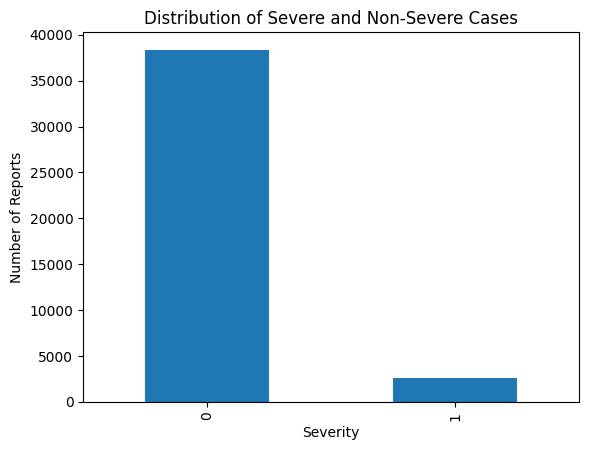

In [33]:
import matplotlib.pyplot as plt

data["SEVERE"].value_counts().plot(kind="bar")
plt.title("Distribution of Severe and Non-Severe Cases")
plt.xlabel("Severity")
plt.ylabel("Number of Reports")
plt.show()

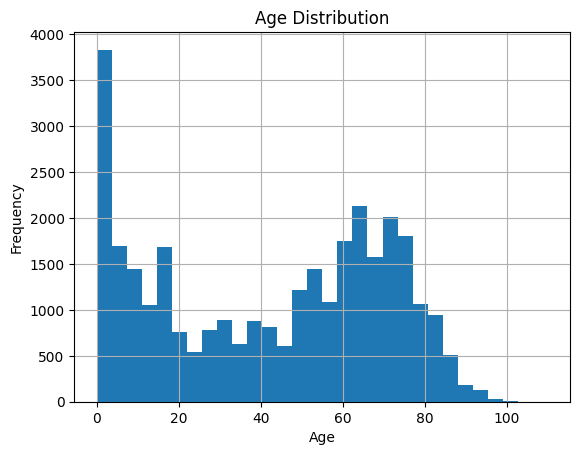

In [34]:
data["AGE_YRS"].hist(bins=30)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

<Axes: xlabel='SEX'>

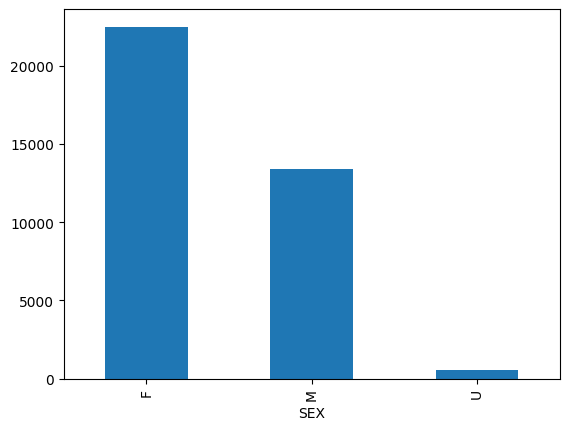

In [35]:
data["SEX"].value_counts().plot(kind="bar")

In [36]:
import pandas as pd

vax = pd.read_csv(
    "/Volumes/Backup Plus/vaccine thesis/data/raw/AllVAERSDataCSVS/2025VAERSVAX.csv",
    encoding="latin1",
    low_memory=False
)
print(vax.shape)
print(vax.columns.tolist())
vax.head()

(54226, 9)
['VAERS_ID', 'VAX_TYPE', 'VAX_MANU', 'VAX_LOT', 'VAX_DOSE_SERIES', 'VAX_ROUTE', 'VAX_SITE', 'VAX_NAME', 'ORDER']


,VAERS_ID,VAX_TYPE,VAX_MANU,VAX_LOT,VAX_DOSE_SERIES,VAX_ROUTE,VAX_SITE,VAX_NAME,ORDER
0,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),2
1,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),2
2,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,2,NaN,NaN,ZOSTER (SHINGRIX),3
3,791393,VARZOS,GLAXOSMITHKLINE BIOLOGICALS,NaN,1,IM,LA,ZOSTER (SHINGRIX),3
4,791747,VARZOS,MERCK & CO. INC.,NaN,UNK,OT,NaN,ZOSTER LIVE (ZOSTAVAX),2


In [37]:
vax["VAX_TYPE"].value_counts().head(20)
covid_vax = vax[vax["VAX_TYPE"] == "COVID19"].copy()

print(covid_vax.shape)
print(covid_vax["VAX_MANU"].value_counts(dropna=False))
print(covid_vax["VAX_NAME"].value_counts().head(20))

(10643, 9)
VAX_MANU
PFIZER\BIONTECH         5439
MODERNA                 4536
UNKNOWN MANUFACTURER     335
JANSSEN                  214
NOVAVAX                  119
Name: count, dtype: int64
VAX_NAME
COVID19 (COVID19 (PFIZER-BIONTECH))      5439
COVID19 (COVID19 (MODERNA))              3912
COVID19 (COVID19 (MODERNA MNEXSPIKE))     623
COVID19 (COVID19 (UNKNOWN))               335
COVID19 (COVID19 (JANSSEN))               214
COVID19 (COVID19 (NOVAVAX))               119
COVID19 (COVID19 (MODERNA UNKNOWN))         1
Name: count, dtype: int64


In [38]:
mrna_vax = covid_vax[
    covid_vax["VAX_MANU"].isin([
        "PFIZER\\BIONTECH",
        "MODERNA"
    ])
].copy()
print(mrna_vax.shape)
print(mrna_vax["VAX_MANU"].value_counts())

(9975, 9)
VAX_MANU
PFIZER\BIONTECH    5439
MODERNA            4536
Name: count, dtype: int64


In [39]:
print("Rows:", len(mrna_vax))
print("Unique reports:", mrna_vax["VAERS_ID"].nunique())

mrna_vax["VAERS_ID"].value_counts().head(10)

Rows: 9975
Unique reports: 9063


VAERS_ID
2820646    7
2827529    7
2862066    6
2845095    6
2867304    6
2846450    6
2826852    6
2834012    6
2850412    6
2836007    5
Name: count, dtype: int64

In [40]:
vax_one = (
    mrna_vax
    .sort_values(["VAERS_ID", "ORDER"])
    .drop_duplicates(subset="VAERS_ID", keep="last")
    [
        [
            "VAERS_ID",
            "VAX_TYPE",
            "VAX_MANU",
            "VAX_NAME",
            "VAX_DOSE_SERIES",
            "VAX_ROUTE",
            "VAX_SITE"
        ]
    ]
)
print(vax_one.shape)
print(vax_one["VAERS_ID"].nunique())

(9063, 7)
9063


In [41]:
merged = data.merge(
    vax_one,
    on="VAERS_ID",
    how="inner",
    validate="many_to_one"
)

In [42]:
print(merged.shape)
print(merged["VAERS_ID"].nunique())
print(merged["VAX_MANU"].value_counts())
print(merged["SEVERE"].value_counts())
print(merged["SEVERE"].value_counts(normalize=True) * 100)

(9217, 43)
9063
VAX_MANU
PFIZER\BIONTECH    5072
MODERNA            4145
Name: count, dtype: int64
SEVERE
0    7829
1    1388
Name: count, dtype: int64
SEVERE
0    84.94087
1    15.05913
Name: proportion, dtype: float64


In [43]:
duplicates = merged[merged.duplicated(subset="VAERS_ID", keep=False)]

duplicates.sort_values("VAERS_ID")

merged["VAERS_ID"].value_counts().head(20)

VAERS_ID
2822006    5
2870850    4
2843927    3
2831857    3
2828902    3
2872141    3
2839075    3
2873922    3
2867321    3
2877530    3
2819423    3
2388264    3
2877267    3
2858237    3
2819959    2
2858573    2
2829599    2
2871907    2
2865422    2
2831442    2
Name: count, dtype: int64

In [44]:
data[data["VAERS_ID"] == 2822006]
vax[vax["VAERS_ID"] == 2822006]

,VAERS_ID,VAX_TYPE,VAX_MANU,VAX_LOT,VAX_DOSE_SERIES,VAX_ROUTE,VAX_SITE,VAX_NAME,ORDER
2862,2822006,COVID19,PFIZER\BIONTECH,NaN,1,IM,LA,COVID19 (COVID19 (PFIZER-BIONTECH)),1
2863,2822006,COVID19,PFIZER\BIONTECH,NaN,1,OT,LA,COVID19 (COVID19 (PFIZER-BIONTECH)),2
2864,2822006,COVID19,PFIZER\BIONTECH,NaN,1,OT,LA,COVID19 (COVID19 (PFIZER-BIONTECH)),3
2865,2822006,COVID19,PFIZER\BIONTECH,NaN,3,NaN,NaN,COVID19 (COVID19 (PFIZER-BIONTECH)),4
2866,2822006,COVID19,UNKNOWN MANUFACTURER,NaN,2,NaN,NaN,COVID19 (COVID19 (UNKNOWN)),4
2867,2822006,COVID19,PFIZER\BIONTECH,NaN,3,NaN,NaN,COVID19 (COVID19 (PFIZER-BIONTECH)),5


In [45]:
vax.groupby("VAERS_ID")["ORDER"].max().head()
for vid in [2822006, 2870850, 2843927]:
    print("="*40)
    print(vax[vax["VAERS_ID"] == vid][["VAERS_ID","ORDER","VAX_MANU","VAX_NAME","VAX_DOSE_SERIES"]])

      VAERS_ID  ORDER              VAX_MANU  \
2862   2822006      1       PFIZER\BIONTECH   
2863   2822006      2       PFIZER\BIONTECH   
2864   2822006      3       PFIZER\BIONTECH   
2865   2822006      4       PFIZER\BIONTECH   
2866   2822006      4  UNKNOWN MANUFACTURER   
2867   2822006      5       PFIZER\BIONTECH   

                                 VAX_NAME VAX_DOSE_SERIES  
2862  COVID19 (COVID19 (PFIZER-BIONTECH))               1  
2863  COVID19 (COVID19 (PFIZER-BIONTECH))               1  
2864  COVID19 (COVID19 (PFIZER-BIONTECH))               1  
2865  COVID19 (COVID19 (PFIZER-BIONTECH))               3  
2866          COVID19 (COVID19 (UNKNOWN))               2  
2867  COVID19 (COVID19 (PFIZER-BIONTECH))               3  
       VAERS_ID  ORDER         VAX_MANU                             VAX_NAME  \
45862   2870850      2  PFIZER\BIONTECH  COVID19 (COVID19 (PFIZER-BIONTECH))   
45863   2870850      3  PFIZER\BIONTECH  COVID19 (COVID19 (PFIZER-BIONTECH))   
45864   28

In [46]:
# Find the latest ORDER for each VAERS_ID
latest_order = (
    vax.groupby("VAERS_ID")["ORDER"]
       .max()
       .reset_index()
)

# Keep only rows with the latest ORDER
vax_latest = vax.merge(
    latest_order,
    on=["VAERS_ID", "ORDER"],
    how="inner"
)

print(vax_latest.shape)
print(vax_latest["VAERS_ID"].nunique())

(53475, 9)
40401


In [47]:
vax_latest["VAERS_ID"].value_counts().head(20)

VAERS_ID
2839751    11
2834584    11
2822405    11
2840232    11
2868124    11
2833167    10
2835135    10
2833508    10
2844908    10
2873195    10
2819815    10
2877685     9
2844094     9
2867977     9
2837917     9
2828616     9
2833463     9
2833465     9
2847747     8
2872288     8
Name: count, dtype: int64

In [48]:
data

,VAERS_ID,RECVDATE,STATE,AGE_YRS,CAGE_YR,CAGE_MO,SEX,RPT_DATE,SYMPTOM_TEXT,DIED,...,PRIOR_VAX,SPLTTYPE,FORM_VERS,TODAYS_DATE,BIRTH_DEFECT,OFC_VISIT,ER_ED_VISIT,ALLERGIES,ORDER,SEVERE
0,2815014,01/01/2025,NJ,37.0,37.0,NaN,F,NaN,received the SHINGRIX vaccine instead of the F...,NaN,...,NaN,USGSKUS2024AMR152842,2,01/01/2025,NaN,NaN,NaN,NaN,2,0
1,2818783,01/01/2025,OH,57.0,57.0,NaN,F,NaN,Pain down arm and weakness for a few days afte...,NaN,...,"soreness in arm after Covid shot, typically la...",NaN,2,01/01/2025,NaN,Y,NaN,percocet,2,0
2,2818864,01/01/2025,OK,1.0,1.0,0.0,U,NaN,No additional AE; HCP called and reported admi...,NaN,...,NaN,US0095075132412USA010369,2,12/31/2024,NaN,NaN,NaN,NaN,1,0
3,2818865,01/01/2025,CO,0.5,NaN,NaN,F,NaN,one of them only received the DTaP-IPV part an...,NaN,...,NaN,USSA2024SA385084,2,12/31/2024,NaN,NaN,NaN,NaN,1,0
4,2818871,01/01/2025,VA,2.0,2.0,0.2,F,NaN,Incorrect storage of drug/received Havrix vacc...,NaN,...,NaN,USGSKUS2024AMR153922,2,01/01/2025,NaN,NaN,NaN,NaN,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40914,2880303,12/31/2025,NaN,77.0,77.0,NaN,F,NaN,Patient already got 1 dose of Arexvy on 11/17/...,NaN,...,NaN,NaN,2,12/31/2025,NaN,NaN,NaN,NaN,1,0
40915,2880304,12/31/2025,WA,13.0,13.0,NaN,F,NaN,Vaccine was given beyond the BUD. BUD was 12/0...,NaN,...,NaN,NaN,2,12/31/2025,NaN,NaN,NaN,NaN,1,0
40916,2880305,12/31/2025,NaN,35.0,35.0,NaN,F,NaN,NOT AVAILABLE AT THIS TIME,NaN,...,NaN,NaN,2,12/31/2025,NaN,NaN,NaN,NaN,1,0
40917,2880307,12/31/2025,NV,21.0,21.0,NaN,F,NaN,Patient received the Tdap vaccine and Flu vacc...,NaN,...,NaN,NaN,2,12/31/2025,NaN,NaN,NaN,NaN,1,0


In [49]:
features = [
    "AGE_YRS",
    "SEX",
    "STATE",
    "RECOVD",
    "NUMDAYS",
    "HISTORY",
    "ALLERGIES"
]
target = "SEVERE"

In [50]:
data[features].isnull().sum()

AGE_YRS       9413
SEX           4503
STATE         6692
RECOVD        4047
NUMDAYS       9770
HISTORY      26701
ALLERGIES    26629
dtype: int64

In [51]:
# Numerical features
data["AGE_YRS"] = data["AGE_YRS"].fillna(data["AGE_YRS"].median())
data["NUMDAYS"] = data["NUMDAYS"].fillna(data["NUMDAYS"].median())

# Categorical features
data["SEX"] = data["SEX"].fillna("Unknown")
data["STATE"] = data["STATE"].fillna("Unknown")
data["RECOVD"] = data["RECOVD"].fillna("Unknown")

# Text features
data["HISTORY"] = data["HISTORY"].fillna("None")
data["ALLERGIES"] = data["ALLERGIES"].fillna("None")

In [52]:
data[[
    "AGE_YRS",
    "SEX",
    "STATE",
    "RECOVD",
    "NUMDAYS",
    "HISTORY",
    "ALLERGIES"
]].isnull().sum()

AGE_YRS      0
SEX          0
STATE        0
RECOVD       0
NUMDAYS      0
HISTORY      0
ALLERGIES    0
dtype: int64

In [53]:
print(data["SEX"].value_counts())
print(data["RECOVD"].value_counts())
print(data["STATE"].value_counts().head(20))
data.to_csv(
    "2025_vaers_cleaned.csv",
    index=False
)

SEX
F          22493
M          13376
Unknown     4503
U            547
Name: count, dtype: int64
RECOVD
U          15271
Y          11321
N          10280
Unknown     4047
Name: count, dtype: int64
STATE
Unknown    6692
CA         3082
FL         2568
TX         2278
MI         1517
NY         1441
PA         1430
GA         1187
OH         1133
NC         1063
VA         1038
IL         1024
MA          902
WA          901
AZ          820
CO          818
TN          790
NJ          769
MD          746
MO          702
Name: count, dtype: int64


In [54]:
data["SEX"] = data["SEX"].replace("U", "Unknown")
data["SEX"].value_counts()

SEX
F          22493
M          13376
Unknown     5050
Name: count, dtype: int64

In [55]:
data["RECOVD"] = data["RECOVD"].replace("U", "Unknown")

In [56]:
data["HISTORY"].sample(20, random_state=42)
data["ALLERGIES"].sample(20, random_state=42)

27804                       None
1077          NO KNOWN ALLERGIES
36764         No known allergies
24677       Biacin, tetracycline
28445                       None
34065                       None
30284                       NKDA
19951    antihistamines, rogaine
9845                        None
28217                       None
23491                       None
12923                       None
18586                       None
2111                        None
35100                      latex
19007                       None
15665                       None
32448                       None
26559                       None
9366                        NKDA
Name: ALLERGIES, dtype: object

In [57]:
data["ALLERGIES"] = data["ALLERGIES"].str.upper().str.strip()

data["ALLERGIES"] = data["ALLERGIES"].replace({
    "NO KNOWN ALLERGIES": "NONE",
    "NKDA": "NONE",
    "NONE": "NONE"
})
data["ALLERGIES"].value_counts().head(20)

ALLERGIES
NONE                       30814
NKA                         1215
NO                           583
PENICILLIN                   324
NONE KNOWN                   251
UNKNOWN                      225
SULFA                        151
AMOXICILLIN                  141
NONE REPORTED                109
NO ALLERGIES                  87
NA                            83
LATEX                         82
CODEINE                       78
NO KNOWN                      74
NO KNOWN DRUG ALLERGIES       71
NONE.                         67
SULFA DRUGS                   58
PENICILLINS                   48
SULFA ANTIBIOTICS             45
N/A                           44
Name: count, dtype: int64

In [58]:
data["HAS_ALLERGY"] = (
    data["ALLERGIES"].fillna("NONE") != "NONE"
).astype(int)
data["HAS_HISTORY"] = (
    data["HISTORY"].fillna("NONE") != "NONE"
).astype(int)

In [59]:
features = [
    "AGE_YRS",
    "SEX",
    "STATE",
    "RECOVD",
    "NUMDAYS",
    "HAS_HISTORY",
    "HAS_ALLERGY"
]

target = "SEVERE"

In [60]:
X = pd.get_dummies(
    data[features],
    columns=["SEX", "STATE", "RECOVD"],
    drop_first=True
)

y = data[target]

In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [62]:
data.to_csv("2025_vaers_cleaned.csv", index=False)

In [63]:
history_clean = (
    data["HISTORY"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.strip()
)

allergy_clean = (
    data["ALLERGIES"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.strip()
)

no_history_values = {
    "", "NONE", "NO", "N/A", "NA", "UNKNOWN",
    "NO HISTORY", "NO MEDICAL HISTORY", "NONE REPORTED"
}

no_allergy_values = {
    "", "NONE", "NO", "N/A", "NA", "UNKNOWN",
    "NKA", "NKDA", "NONE KNOWN", "NO ALLERGIES",
    "NO KNOWN", "NO KNOWN ALLERGIES",
    "NO KNOWN DRUG ALLERGIES", "NONE REPORTED", "NONE."
}

data["HAS_HISTORY"] = (~history_clean.isin(no_history_values)).astype(int)
data["HAS_ALLERGY"] = (~allergy_clean.isin(no_allergy_values)).astype(int)

print("Medical history:")
print(data["HAS_HISTORY"].value_counts())

print("\nAllergies:")
print(data["HAS_ALLERGY"].value_counts())

Medical history:
HAS_HISTORY
0    30180
1    10739
Name: count, dtype: int64

Allergies:
HAS_ALLERGY
0    33623
1     7296
Name: count, dtype: int64


In [64]:
features = [
    "AGE_YRS",
    "SEX",
    "STATE",
    "NUMDAYS",
    "HAS_HISTORY",
    "HAS_ALLERGY"
]

target = "SEVERE"

X = pd.get_dummies(
    data[features],
    columns=["SEX", "STATE"],
    drop_first=True
)

y = data[target]

print("X shape:", X.shape)

print("\nTarget counts:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

X shape: (40919, 62)

Target counts:
SEVERE
0    38368
1     2551
Name: count, dtype: int64

Target proportions:
SEVERE
0    0.937657
1    0.062343
Name: proportion, dtype: float64


In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining severe proportion:")
print(y_train.value_counts(normalize=True))

print("\nTest severe proportion:")
print(y_test.value_counts(normalize=True))

Training set: (32735, 62)
Test set: (8184, 62)

Training severe proportion:
SEVERE
0    0.937651
1    0.062349
Name: proportion, dtype: float64

Test severe proportion:
SEVERE
0    0.937683
1    0.062317
Name: proportion, dtype: float64


In [66]:
data.to_csv("2025VAERSDATA_cleaned.csv", index=False)
model_data = X.copy()
model_data["SEVERE"] = y.values

model_data.to_csv("vaers_2025_model_data.csv", index=False)

In [67]:
data.to_csv(
    "../data/processed/2025VAERSDATA_cleaned.csv",
    index=False
)

model_data = X.copy()
model_data["SEVERE"] = y.values

model_data.to_csv(
    "../data/processed/vaers_2025_model_data.csv",
    index=False
)